#  Ships and Helicopter Image Generation
Final Exam Deep Learning   
Ellyn Auria

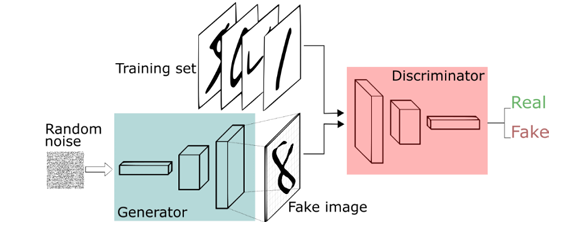

GAN (Generative Adversarial Network) adalah arsitektur deep learning yang terdiri dari dua neural network, yaitu Generator dan Discriminator, yang saling berkompetisi (adversarial) untuk menghasilkan fak image yang menyerupai real image.
1. Generator (Pembuat Gambar)   
Input dari generator merupakan random noise (vektor acak). Noise ini sebagai titik awal seed yang tidak memiliki makna visual apapun. Kemudian generator menggunakan jaringan artificial network biasanya deconvolutional layers, lalu memproses dan mengubah noise tersebut langkah demi langkah menjadi gambar yang terstruktur. Output yang dihasilkan adalah fake image yang dibuat berdasarkan random noise.
2. Discriminator (Pembeda gambar)   
Input dari discriminator ada 2 yaitu training set dan fake image yang telah dibuat oleh generator. Training set merupakan gambar asli yang berasal dari dunia nyata (pada gambar merupakan tulisan tangan asli). Sedangkan fake image adalah tulisan tangan yang telah dibuat oleh generator. Discriminator bertindak sebagai klasifikator gambar yang menggunakan CNN. Prosesnya adalah mengekstrak fitur dari gambar yang diinputkan lalu mencari tahu apakah ada kejanggalan atau pola buatan. Output dari discriminator adalah probabilitas klasifikasi "Real" atau "Fake". 
3. Adversarial Process   
Keduanya antara generator dan discriminator ditraining secara bersamaan. Saat generator membuat fake image yang buruk maka discriminator dengan mudah mengklasifikasikan sebagai "Fake". Berdasarkan kegagalan ini, generator akan menerima feedback dan memperbarui bobot untuk membuat gambar yang lebih baik di iterasi berikutnya. Tujuan generator adalah memaksimalkan peluang discriminator menganggap fake image adalah real image/menipu discriminator.      
Di saat yang sama, karena generator semakin pintar membuat gambar, discriminator juga harus memperbarui bobot supaya lebih teliti dalam mendeteksi fake image. Tujuan discriminator adalah meminimalkan kesalahan klasifikasi image.     
Proses ini terus berulang sampai titik keseimbangan (equilibrium) di mana generator akan membuat fake image sampai discriminator tidak bisa membedakan "Real" atau "Fake" (probability 50/50).

## Import Libraries

In [ ]:
from __future__ import print_function
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.backends.cudnn as cudnn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import torchvision.utils as vutils
import torch.nn.utils as utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
from torchvision.models import inception_v3, Inception_V3_Weights

In [155]:
#manual seed
manualSeed = 42
print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
torch.cuda.manual_seed(manualSeed)
torch.cuda.manual_seed_all(manualSeed)
np.random.seed(manualSeed)
cudnn.deterministic = True
cudnn.benchmark = False

Random Seed:  42


In [156]:
#konfigurasi parameter global
img_size = 28 
img_flat_dim = img_size ** 2
num_classes = 10
latent_dim = 100
batch_size = 64
num_epochs = 100
lr = 0.0002
num_channel = 1
beta1 = 0.5

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

label_ship = 7
label_helicopter = 2

## Loading Train Data

In [157]:
train = pd.read_csv('train.csv')

In [158]:
train

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,8,86,91,98,97,96,89,76,84,87,...,76,81,80,72,77,83,71,44,53,33
1,3,128,133,129,119,114,128,141,131,133,...,137,129,139,161,128,137,131,125,127,135
2,0,138,117,84,52,38,62,86,75,101,...,63,99,109,83,61,54,75,98,107,108
3,6,105,108,108,109,111,112,107,104,106,...,120,115,105,89,87,98,92,95,89,84
4,5,176,143,109,155,151,149,145,152,156,...,92,85,82,91,80,80,79,79,82,85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8514,9,100,103,99,92,90,87,79,75,76,...,56,56,61,67,80,91,112,88,85,106
8515,0,70,79,92,96,86,74,68,64,65,...,53,35,29,38,56,73,84,75,65,57
8516,7,188,220,199,113,216,215,49,9,104,...,8,5,2,24,40,36,37,39,40,41
8517,0,52,48,34,27,24,22,30,36,53,...,22,29,47,77,118,152,153,153,159,164


Data training terdiri dari 8519 baris dan 785 kolom

Melakukan filter untuk ship dan helocopter dan pemisahan antara label dan images

In [159]:
#filter label 2 dan 7 untuk ship dan helicopter
df_train = train[train['label'].isin([label_ship, label_helicopter])]

train_labels = df_train.iloc[:, 0].values
train_images = df_train.iloc[:, 1:].values.astype(np.float32)

Melakukan scaling agar pixel menjadi rentangnya -1 sampai 1

In [160]:
#scaling menjadi [-1, 1]
train_images = (train_images / 255.0) * 2.0 - 1.0

In [161]:
#ubah menjadi tensor
train_images = torch.tensor(train_images, dtype=torch.float32)
train_labels = torch.tensor(train_labels, dtype=torch.long)

#reshape images menjadi 4D
train_images = train_images.reshape(-1, 1, img_size, img_size)

In [162]:
print(train_images.shape)
print(train_labels.shape)

torch.Size([1544, 1, 28, 28])
torch.Size([1544])


## Load Test Data

In [163]:
test = pd.read_csv('test.csv')

In [164]:
test

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,5,198,225,234,229,230,228,214,244,107,...,209,222,211,196,216,206,192,212,242,254
1,1,34,35,30,17,16,22,11,42,137,...,36,41,32,33,34,37,33,36,35,37
2,4,113,176,239,250,247,231,177,181,178,...,70,85,158,189,150,168,148,181,154,54
3,3,151,129,173,182,140,119,120,115,112,...,136,118,126,130,124,119,134,126,121,122
4,7,186,159,233,255,255,227,140,110,113,...,131,149,108,87,120,131,138,137,137,139
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,1,37,36,39,39,39,40,39,40,42,...,37,36,35,36,34,32,33,35,34,37
1061,8,45,49,45,58,74,72,69,64,55,...,33,47,54,56,58,55,50,47,45,45
1062,7,110,120,164,147,99,140,164,141,174,...,127,124,126,125,126,129,128,124,123,125
1063,0,15,9,10,14,18,30,55,75,79,...,41,29,26,33,37,33,32,33,31,27


In [165]:
#filter label 2 dan 7 untuk ship dan helicopter
df_test = test[test['label'].isin([label_ship, label_helicopter])]

test_labels = df_test.iloc[:, 0].values
test_images = df_test.iloc[:, 1:].values.astype(np.float32)

In [166]:
#scaling menjadi [-1, 1]
test_images = (test_images / 255.0) * 2.0 - 1.0

In [167]:
#ubah menjadi tensor
test_images = torch.tensor(test_images, dtype=torch.float32)
test_labels = torch.tensor(test_labels, dtype=torch.long)

#reshape images menjadi 4D
test_images = test_images.reshape(-1, 1, img_size, img_size)

In [168]:
print(test_images.shape)
print(test_labels.shape)

torch.Size([193, 1, 28, 28])
torch.Size([193])


## Inisialisasi Dataloader

In [169]:
#tensor dataset
train_dataset = TensorDataset(train_images, train_labels)
test_dataset = TensorDataset(test_images, test_labels)

#inisialisasi dataloader
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_loader = DataLoader(test_dataset, batch_size=batch_size,shuffle=False)

Data loader dilakukan untuk memudahkan data supaya diproses lebih efisien pada saat training dan pengujian model.

## Inisialisasi Weight

In [170]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Linear') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0)

inisialisasi weight digunakan untuk memberikan nilai awal pada neural network sebelum training dimulai. Layer linear diinisialisasi dengan weight diisi menggunakan distribusi normal dengan mean = 0 dan standar deviasi 0.02, sedangkan bias diinsialisasi dengan nilai 0. 

In [244]:
#Batch vektor laten tetap (2D untuk Fully Connected)
fixed_noise = torch.randn(64, latent_dim, device=device)
# Label tetap yang berulang dari angka 0-9 untuk visualisasi cGAN
fixed_labels = torch.tensor([i % 10 for i in range(64)], dtype=torch.long, device=device)

Membuat input tetap yang digunakan untuk mengevaluasi train generator. fixed_noise berisi 64 vektor laten acak yang akan menjadi masukan Generator, sedangkan fixed_labels berisi 64 label kelas yang berulang dari 0 hingga 9.

## Arsitektur Baseline

In [172]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)
        self.main = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 128),
            nn.ReLU(True),
            nn.Linear(128, 256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.Linear(1024, img_flat_dim),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_input = self.label_emb(labels)
        x = torch.cat((noise, label_input), dim=1)
        output = self.main(x)
        return output.view(-1, 1, img_size, img_size)

Generator terdiri dari beberapa lapisan Fully Connected (Linear) yang berfungsi mengubah vektor noise menjadi fake image sesuai dengan label kelas yang diberikan. Pada tahap awal, label kelas direpresentasikan dalam bentuk vektor menggunakan Embedding Layer (nn.Embedding), kemudian digabungkan (concatenate) dengan vektor laten (noise) sehingga membentuk satu vektor input berukuran latent_dim + num_classes. Vektor gabungan tersebut selanjutnya diproses secara bertahap melalui lima layer Linear dengan jumlah neuron 128, 256, 512, 1024, dan img_flat_dim, di mana setiap lapisan diikuti oleh fungsi aktivasi ReLU untuk memperkenalkan non-linearitas dan membantu model mempelajari representasi yang lebih kompleks. Pada layer output digunakan fungsi aktivasi Tanh sehingga nilai piksel hasil generator berada pada rentang -1 hingga 1, sesuai dengan proses scaling image selama training. Terakhir, output yang semula berbentuk vektor satu dimensi diubah reshape menjadi image berukuran 1 × img_size × img_size, sehingga menghasilkan gambar grayscale yang dapat dievaluasi oleh discriminator.

In [173]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)
        self.main = nn.Sequential(
            nn.Linear(num_classes + (img_flat_dim), 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1),
            nn.Sigmoid() 
        )

    def forward(self, img, labels):
        img_flat = img.view(img.size(0), -1)
        label_input = self.label_emb(labels)
        x = torch.cat((img_flat, label_input), dim=1)
        return self.main(x)

Discriminator bertugas membedakan apakah suatu gambar merupakan gambar asli (real) atau hasil generasi (fake) dengan mempertimbangkan informasi label kelas. Pada tahap awal, label kelas direpresentasikan menjadi vektor menggunakan Embedding Layer (nn.Embedding), kemudian gambar input diubah menjadi vektor satu dimensi (flatten) menggunakan view() dan digabungkan (concatenate) dengan vektor label sehingga membentuk satu vektor masukan berukuran img_flat_dim + num_classes. Vektor tersebut kemudian diproses melalui lima lapisan Fully Connected (Linear) dengan jumlah neuron 512, 1024, 1024, 512, dan 1, di mana setiap hidden layer menggunakan fungsi aktivasi LeakyReLU dengan nilai negative slope sebesar 0,2 untuk mengatasi permasalahan dying ReLU dan menjaga aliran gradien selama pelatihan. Pada output layer digunakan fungsi aktivasi Sigmoid yang menghasilkan nilai probabilitas pada rentang 0 hingga 1

In [174]:
def get_inception_features(images, inception_model, batch_size=64, device='cuda'):
    inception_model.eval()
    features = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = images[i:i+batch_size].to(device)
            #ubah grayscale menjadi rgb
            if batch.shape[1] == 1:
                batch = batch.repeat(1, 3, 1, 1)
            #resize ke ukuran inception
            batch = F.interpolate(
                batch,
                size=(299, 299),
                mode='bilinear',
                align_corners=False)
            pred = inception_model(batch)
            features.append(pred.cpu().numpy())
    features = np.concatenate(features, axis=0)
    mu = np.mean(features, axis=0)
    sigma = np.cov(features, rowvar=False)
    return mu, sigma

Fungsi get_inception_features() bertugas mengekstraksi representasi fitur dari sekumpulan gambar menggunakan model InceptionV3. Sebelum ekstraksi, gambar grayscale diubah menjadi tiga channel (RGB) dan di-resize menjadi 299 × 299 agar sesuai dengan spesifikasi input InceptionV3. Fitur yang dihasilkan kemudian digabungkan untuk menghitung vektor rata-rata (mean) dan matriks kovarians (covariance). Keduanya menjadi dasar dalam perhitungan FID.

In [175]:
def calculate_fid(mu1, sigma1, mu2, sigma2, eps=1e-6):
    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)

    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)

    diff = mu1 - mu2
    covmean, _ = sqrtm(sigma1 @ sigma2, disp=False)

    #mengatasi singular covariance
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = sqrtm((sigma1 + offset) @ (sigma2 + offset))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    fid = (
        diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2 * np.trace(covmean))
    return float(fid)

Fungsi calculate_fid() digunakan untuk menghitung Frechet Inception Distance (FID), yaitu metrik evaluasi yang mengukur perbedaan distribusi fitur antara gambar asli dan gambar hasil generator berdasarkan vektor rata-rata (mean) dan matriks kovarians (covariance) yang diperoleh dari model InceptionV3. Fungsi ini terlebih dahulu memastikan bentuk data sesuai, kemudian menghitung selisih rata-rata fitur, akar matriks dari hasil perkalian kovarians, serta menangani potensi masalah numerik seperti singular covariance dan munculnya bilangan kompleks. Selanjutnya, seluruh komponen tersebut digunakan untuk menghitung nilai FID sesuai rumus Frechet Distance.

In [176]:
def evaluate_current_fid(generator, dataloader, latent_dim, device='cuda'):
    generator.eval()

    inception = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=False)
    inception.fc = nn.Identity()
    inception.to(device)
    inception.eval()

    real_images = []
    fake_images = []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(device)
            labels = labels.to(device)
            batch_size = imgs.size(0)
            noise = torch.randn(batch_size, latent_dim, device=device)
            fake = generator(noise, labels)
            real_images.append(imgs.cpu())
            fake_images.append(fake.cpu())
    real_images = torch.cat(real_images, dim=0)
    fake_images = torch.cat(fake_images, dim=0)

    mu_real, sigma_real = get_inception_features(real_images, inception, device=device)
    mu_fake, sigma_fake = get_inception_features(fake_images, inception, device=device)

    fid = calculate_fid(mu_real, sigma_real, mu_fake, sigma_fake)

    return fid

Fungsi ini terlebih dahulu mengubah Generator dan model InceptionV3 ke mode evaluasi, kemudian menghasilkan gambar sintetis menggunakan kombinasi noise acak dan label kelas yang diambil dari DataLoader. Selanjutnya, baik gambar asli maupun gambar hasil Generator diekstraksi fiturnya menggunakan InceptionV3 untuk memperoleh vektor rata-rata (mean) dan matriks kovarians (covariance). Kedua statistik tersebut kemudian digunakan dalam fungsi calculate_fid() untuk memperoleh nilai FID

In [ ]:
def training_loop(num_epochs=num_epochs, saturating=False):
    #inisialisasi model
    netG = Generator().to(device)
    netG.apply(weights_init)

    netD = Discriminator().to(device)
    netD.apply(weights_init)

    #inisialisasi fungsi loss dan optimizer
    criterion = nn.BCELoss()
    optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
    optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

    img_list = []
    G_losses = []
    D_losses = []
    G_grads_mean = []
    G_grads_std = []

    #perulangan epoch
    for epoch in range(num_epochs):
        epoch_g_loss = 0.0
        epoch_d_loss = 0.0
        epoch_grad_mean = []
        epoch_grad_std = []

        for i, (real_images, labels) in enumerate(train_loader, 0):
            
            #train discriminator
            optimizerD.zero_grad()
            real_images = real_images.to(device)
            labels = labels.to(device)
            b_size = real_images.size(0)
            real_target = torch.ones(b_size, device=device)
            fake_target = torch.zeros(b_size, device=device)

            output_real = netD(real_images, labels).view(-1)
            errD_real = criterion(output_real, real_target)
            errD_real.backward()
            D_x = output_real.mean().item()

            noise = torch.randn(b_size, latent_dim, device=device)
            fake_images = netG(noise, labels)
            output_fake = netD(fake_images.detach(), labels).view(-1)
            errD_fake = criterion(output_fake, fake_target)
            errD_fake.backward()
            D_G_z1 = output_fake.mean().item()
            
            errD = errD_real + errD_fake
            optimizerD.step()

            #train generator
            optimizerG.zero_grad()
            output = netD(fake_images, labels).view(-1)

            if saturating:
                errG = criterion(output, fake_target)
            else:
                errG = criterion(output, real_target)

            #pengambilan statistik gradien generator
            errG.backward()

            grads = []

            for p in netG.parameters():
                if p.grad is not None:
                    grads.append(p.grad.detach().view(-1).cpu().numpy())

            grads = np.concatenate(grads)
            epoch_grad_mean.append(grads.mean())
            epoch_grad_std.append(grads.std())
            optimizerG.step()

            D_G_z2 = output.mean().item()

            epoch_g_loss += errG.item()
            epoch_d_loss += errD.item()

            #menyampaikan informasi training
            if i % 20 == 0:
                print(
                    f"Epoch [{epoch+1}/{num_epochs}] "
                    f"Batch [{i}/{len(train_loader)}] "
                    f"Loss_D: {errD.item():.4f} "
                    f"Loss_G: {errG.item():.4f} "
                    f"D(x): {D_x:.4f} "
                    f"D(G(z)): {D_G_z1:.4f}/{D_G_z2:.4f}"
                )

            #penyimpanan nilai loss
            G_losses.append(epoch_g_loss / len(train_loader))
            D_losses.append(epoch_d_loss / len(train_loader))
            G_grads_mean.append(np.mean(epoch_grad_mean))
            G_grads_std.append(np.mean(epoch_grad_std))

            #menyimpan hasil gambar generator
            with torch.no_grad():
                fake_display = netG(fixed_noise, fixed_labels).detach().cpu()

            img_grid = vutils.make_grid(fake_display,padding=2,normalize=True)
            img_list.append(img_grid)

            #ringkasan setiap epoch
            print(
                f"\nEpoch {epoch+1}/{num_epochs}"
                f" | D Loss: {D_losses[-1]:.4f}"
                f" | G Loss: {G_losses[-1]:.4f}\n"
            )

    return netG, G_losses, D_losses, G_grads_mean, G_grads_std, img_list

Fungsi training_loop() dilakukan inisialisasi Generator dan Discriminator beserta bobot awalnya, pendefinisian fungsi loss dan optimizer, kemudian proses pelatihan selama sejumlah epoch yang telah ditentukan. Pada setiap iterasi, Discriminator dilatih terlebih dahulu untuk membedakan gambar asli dan gambar hasil Generator, kemudian Generator dilatih untuk menghasilkan gambar yang mampu mengelabui Discriminator. Selama proses pelatihan, nilai loss Generator dan Discriminator, statistik gradien Generator, serta gambar hasil generasi disimpan untuk digunakan pada proses evaluasi dan visualisasi perkembangan model.

In [178]:
#training saturation loss
netG_sat, G_losses_sat, D_losses_sat, G_grads_mean_sat, G_grads_std_sat, img_list_sat = training_loop(saturating=True)

#training non saturation loss
netG_nonsat, G_losses_nonsat, D_losses_nonsat, G_grads_mean_nonsat, G_grads_std_nonsat, img_list_nonsat = training_loop(saturating=False)

Epoch [1/100] Batch [0/25] Loss_D: 1.3906 Loss_G: 0.6948 D(x): 0.4977 D(G(z)): 0.4998/0.5008

Epoch 1/100 | D Loss: 0.0556 | G Loss: 0.0278


Epoch 1/100 | D Loss: 0.1101 | G Loss: 0.0557


Epoch 1/100 | D Loss: 0.1636 | G Loss: 0.0836


Epoch 1/100 | D Loss: 0.2154 | G Loss: 0.1117


Epoch 1/100 | D Loss: 0.2650 | G Loss: 0.1399


Epoch 1/100 | D Loss: 0.3109 | G Loss: 0.1681


Epoch 1/100 | D Loss: 0.3525 | G Loss: 0.1962


Epoch 1/100 | D Loss: 0.3891 | G Loss: 0.2239


Epoch 1/100 | D Loss: 0.4221 | G Loss: 0.2511


Epoch 1/100 | D Loss: 0.4521 | G Loss: 0.2777


Epoch 1/100 | D Loss: 0.4803 | G Loss: 0.3035


Epoch 1/100 | D Loss: 0.5063 | G Loss: 0.3277


Epoch 1/100 | D Loss: 0.5296 | G Loss: 0.3483


Epoch 1/100 | D Loss: 0.5475 | G Loss: 0.3617


Epoch 1/100 | D Loss: 0.5575 | G Loss: 0.3663


Epoch 1/100 | D Loss: 0.5602 | G Loss: 0.3669


Epoch 1/100 | D Loss: 0.5606 | G Loss: 0.3670


Epoch 1/100 | D Loss: 0.5614 | G Loss: 0.3671


Epoch 1/100 | D Loss: 0.5620 | G Loss: 0.3

### Plot perbandingan loss

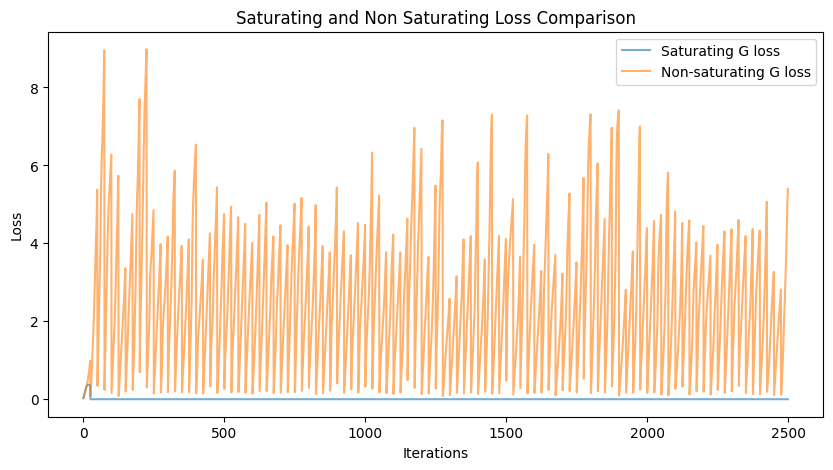

In [211]:
plt.figure(figsize=(10,5))
plt.title("Saturating and Non Saturating Loss Comparison")
plt.plot(G_losses_sat, label="Saturating G loss", alpha=0.6)
plt.plot(G_losses_nonsat, label="Non-saturating G loss", alpha=0.6)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

Grafik saturating cepat datar menunjukkan generator mengalami vanishing gradient sehingga pembelajaran sangat lambat dan berhenti. Sedangkan Non saturating berfluktuasi menunjukkan generator aktif belajar dan terus menyesuaikan parameternya.

### Plot rata-rata gradien generator

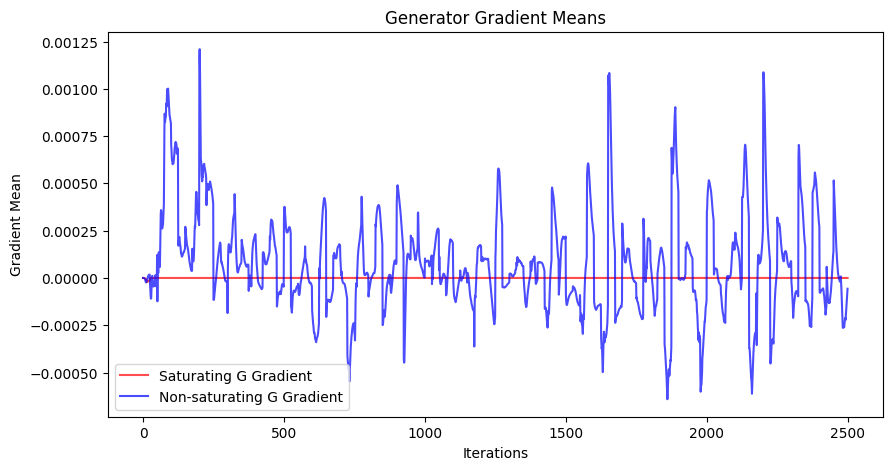

In [184]:
plt.figure(figsize=(10,5))
plt.title("Generator Gradient Means")
plt.plot(G_grads_mean_sat, label="Saturating G Gradient", color='r', alpha=0.7)
plt.plot(G_grads_mean_nonsat, label="Non-saturating G Gradient", color='b', alpha=0.7)
plt.xlabel("Iterations")
plt.ylabel("Gradient Mean")
plt.legend()
plt.show()

Pada saturating, nilai mean gradien dengan cepat mendekati 0, kondisi ini menandakan vanishing gradien. Akibatnya, kemampuan Generator untuk meningkatkan kualitas gambar menjadi terbatas. Sebalikknya pada non saturating, nilai mean gradien terus berfluktuasi dan sesekali bernilai negatif. Fluktuasi tersebut menunjukkan bahwa Generator masih menerima sinyal pembelajaran yang cukup untuk memperbarui parameternya

### Perhitungan FID

In [185]:
fid_sat = evaluate_current_fid(netG_sat, test_loader, latent_dim, device=device)
fid_nonsat = evaluate_current_fid(netG_nonsat, test_loader, latent_dim, device=device)

print(f"FID saturating loss: {fid_sat:.4f}")
print(f"FID non-saturating loss: {fid_nonsat:.4f}")

FID saturating loss: 490.0497
FID non-saturating loss: 413.6244


Berdasarkan hasil evaluasi menggunakan FID, Non-Saturating Loss memberikan performa yang lebih baik dibandingkan Saturating Loss pada model baseline. Hal ini ditunjukkan oleh nilai FID yang lebih rendah, yaitu 413,6244 dibandingkan 490,0497. Hasil tersebut mengindikasikan bahwa distribusi fitur gambar yang dihasilkan oleh Generator dengan Non-Saturating Loss lebih mendekati distribusi gambar asli. Temuan ini juga konsisten dengan hasil analisis grafik Generator Loss dan mean gradien Generator, yang menunjukkan bahwa Non-Saturating Loss mampu mempertahankan aliran gradien sehingga proses pembelajaran Generator berlangsung lebih efektif.

### Perbandingan Real vs Fake

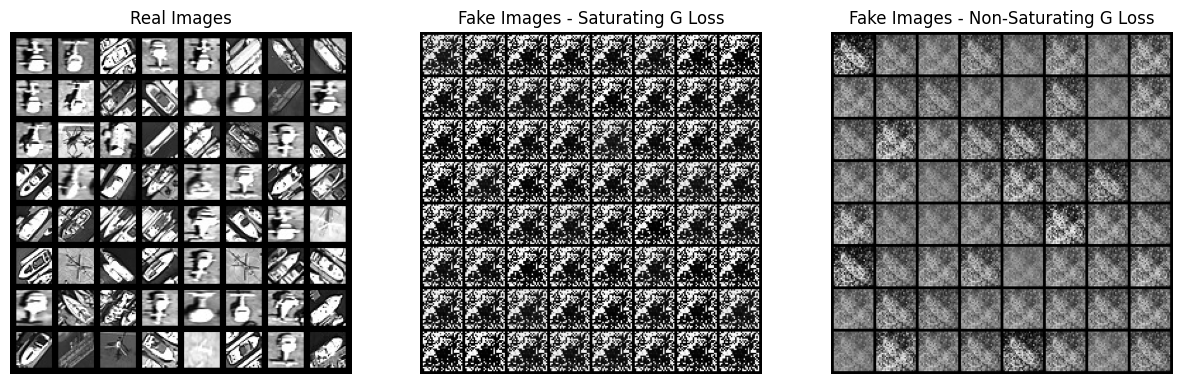

In [241]:
real_batch = next(iter(train_loader))
plt.figure(figsize=(15,15))

plt.subplot(1, 3, 1)
plt.axis("off")
plt.title("Real Images")
# make_grid menyatukan 64 gambar pertama, normalize=True mengembalikan skala [-1,1] ke [0,1]
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=5, normalize=True).cpu(), (1, 2, 0)))

plt.subplot(1, 3, 2)
plt.axis("off")
plt.title("Fake Images - Saturating G Loss")
# Mengambil indeks terakhir [-1] dari history gambar buatan selama latihan
plt.imshow(np.transpose(img_list_sat[-1], (1, 2, 0)))

plt.subplot(1, 3, 3)
plt.axis("off")
plt.title("Fake Images - Non-Saturating G Loss")
plt.imshow(np.transpose(img_list_nonsat[-1], (1, 2, 0)))

plt.show()

Di sini terlihat bahwa fake image masih belum menampilkan hasil yang mirip dengan real image.

## Arsitektur Modified

In [225]:
class GeneratorModified(nn.Module):
    def __init__(self):
        super(GeneratorModified, self).__init__()
        self.label_embedding_modified = nn.Embedding(num_classes,num_classes)
        self.init_size_modified = img_size // 4

        # Fully Connected pertama
        self.fc_modified = nn.Sequential(
            nn.Linear(latent_dim + num_classes,128 * self.init_size_modified * self.init_size_modified))

        # Convolution Block
        self.conv_blocks_modified = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128,128,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128,64,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64,1,kernel_size=3,stride=1,padding=1),
            nn.Tanh())

    def forward(self, noise_modified, labels_modified):
        label_vector_modified = self.label_embedding_modified(labels_modified)
        generator_input_modified = torch.cat(
            (noise_modified, label_vector_modified),dim=1)
        feature_map_modified = self.fc_modified(generator_input_modified)
        feature_map_modified = feature_map_modified.view(
            feature_map_modified.size(0),128,self.init_size_modified,self.init_size_modified)
        generated_image_modified = self.conv_blocks_modified(feature_map_modified)

        return generated_image_modified

Pada tahap awal generator, label kelas direpresentasikan menjadi vektor menggunakan Embedding Layer (nn.Embedding), kemudian digabungkan (concatenate) dengan vektor noise (latent vector) sebagai masukan Generator. Vektor gabungan tersebut diproses oleh sebuah Fully Connected Layer yang menghasilkan feature map awal berukuran 128 × 7 × 7 (karena init_size = img_size // 4 untuk citra berukuran 28×28). Selanjutnya, feature map diproses melalui beberapa Convolution Blocks yang terdiri atas Batch Normalization, Upsampling, Convolutional Layer, dan fungsi aktivasi ReLU. Proses upsampling dilakukan dua kali untuk memperbesar ukuran feature map dari 7 × 7 menjadi 14 × 14, kemudian menjadi 28 × 28, sedangkan Convolutional Layer digunakan untuk mempelajari pola spasial pada citra dan mengurangi jumlah kanal dari 128 menjadi 64, kemudian menjadi 1 kanal sebagai citra grayscale. Setiap lapisan konvolusi diikuti oleh Batch Normalization untuk menstabilkan distribusi aktivasi dan mempercepat proses pelatihan, serta fungsi aktivasi ReLU untuk meningkatkan kemampuan model dalam mempelajari hubungan nonlinier. Pada layer output digunakan fungsi aktivasi Tanh sehingga nilai piksel hasil generasi berada pada rentang −1 hingga 1, sesuai dengan proses normalisasi data masukan.

In [226]:
class DiscriminatorModified(nn.Module):
    def __init__(self):
        super(DiscriminatorModified, self).__init__()
        self.label_embedding_modified = nn.Embedding(num_classes, img_flat_dim)
        self.feature_extractor_modified = nn.Sequential(
            utils.spectral_norm(
                nn.Conv2d(2,64,kernel_size=3,stride=2,padding=1)),
            nn.LeakyReLU(0.2,inplace=True),
            utils.spectral_norm(
                nn.Conv2d(64,128,kernel_size=3,stride=2,padding=1)),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2,inplace=True),
            utils.spectral_norm(
                nn.Conv2d(128,256,kernel_size=3,stride=2,padding=1)),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2,inplace=True))
        self.classifier_modified = nn.Sequential(
            nn.Linear(256 * 4 * 4,1),
            nn.Sigmoid())

    def forward(self,image_modified,labels_modified):
        label_map_modified = self.label_embedding_modified(labels_modified )
        label_map_modified = label_map_modified.view(labels_modified.size(0),1,img_size,img_size)
        discriminator_input_modified = torch.cat(
            (image_modified,label_map_modified),dim=1)
        extracted_feature_modified = self.feature_extractor_modified(discriminator_input_modified)
        extracted_feature_modified = extracted_feature_modified.view(extracted_feature_modified.size(0),-1)
        output_modified = self.classifier_modified(extracted_feature_modified)

        return output_modified

Pada tahap awal discriminator, label kelas direpresentasikan menggunakan Embedding Layer (nn.Embedding) menjadi sebuah vektor berukuran sama dengan dimensi citra (img_flat_dim), kemudian diubah (reshape) menjadi label map berukuran 1 × 28 × 28 dan digabungkan (concatenate) dengan citra masukan sehingga menghasilkan input dengan 2 channel, yaitu satu channel untuk citra dan satu channel untuk informasi label. Input tersebut kemudian diproses melalui tiga Convolutional Layer dengan jumlah filter berturut-turut 64, 128, dan 256, menggunakan kernel berukuran 3×3, stride 2, dan padding 1 untuk mengekstraksi fitur sekaligus mengurangi dimensi spasial citra. Setiap lapisan konvolusi menerapkan Spectral Normalization untuk membatasi nilai singular maksimum pada bobot sehingga proses pelatihan Discriminator menjadi lebih stabil dan mengurangi risiko ketidakseimbangan antara Generator dan Discriminator. Selain itu, pada lapisan kedua dan ketiga digunakan Batch Normalization untuk mempercepat konvergensi dan menjaga kestabilan distribusi aktivasi, sedangkan fungsi aktivasi LeakyReLU dengan negative slope sebesar 0,2 digunakan pada setiap lapisan tersembunyi untuk mengatasi permasalahan dying ReLU dan menjaga aliran gradien. Feature map hasil ekstraksi kemudian di-flatten menjadi vektor satu dimensi dan diteruskan ke Fully Connected Layer yang menghasilkan satu nilai keluaran. Pada lapisan terakhir digunakan fungsi aktivasi Sigmoid untuk menghasilkan probabilitas pada rentang 0 hingga 1, di mana nilai yang mendekati 1 menunjukkan bahwa citra diprediksi sebagai citra asli (real), sedangkan nilai yang mendekati 0 menunjukkan bahwa citra diprediksi sebagai citra hasil generasi (fake).

In [227]:
def weights_init_modified(model):
    classname = model.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(model.weight.data,0.0,0.02)
        if model.bias is not None:
            nn.init.constant_(model.bias.data,0)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(model.weight.data,1.0,0.02)
        nn.init.constant_(model.bias.data,0)
    elif classname.find("Linear") != -1:
        nn.init.xavier_normal_(model.weight.data)
        if model.bias is not None:
            nn.init.constant_(model.bias.data,0)

Fungsi weights_init_modified() melakukan inisialisasi bobot sesuai dengan karakteristik masing-masing jenis layer. Convolutional Layer diinisialisasi menggunakan Normal Initialization dengan rata-rata 0 dan standar deviasi 0,02, Batch Normalization Layer menggunakan Normal Initialization dengan rata-rata 1 dan standar deviasi 0,02 untuk parameter skala serta bias bernilai 0, sedangkan Fully Connected Layer menggunakan Xavier Normal Initialization dengan bias bernilai 0. Pendekatan ini lebih sesuai untuk arsitektur berbasis CNN dibandingkan menggunakan satu metode inisialisasi yang sama untuk seluruh layer, karena setiap jenis layer memiliki karakteristik dan kebutuhan yang berbeda. Dengan inisialisasi yang tepat, proses pelatihan menjadi lebih stabil, konvergensi model lebih cepat, serta risiko terjadinya vanishing gradient maupun exploding gradient dapat dikurangi.

In [228]:
netG_modified = GeneratorModified().to(device)
netD_modified = DiscriminatorModified().to(device)

netG_modified.apply(weights_init_modified)
netD_modified.apply(weights_init_modified)

print(netG_modified)
print()
print(netD_modified)

GeneratorModified(
  (label_embedding_modified): Embedding(10, 10)
  (fc_modified): Sequential(
    (0): Linear(in_features=110, out_features=6272, bias=True)
  )
  (conv_blocks_modified): Sequential(
    (0): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): Upsample(scale_factor=2.0, mode='nearest')
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): Tanh()
  )
)

DiscriminatorModified(
  (label_embedding_modified): Embedding(10, 784)
  (feature_extractor_modified): Sequential(
   

In [229]:
noise_modified = torch.randn(4, latent_dim).to(device)
labels_modified = torch.tensor([2, 2, 7, 7]).to(device)

fake_images_modified = netG_modified(
    noise_modified,
    labels_modified
)

print(fake_images_modified.shape)

torch.Size([4, 1, 28, 28])


In [230]:
decision_modified = netD_modified(
    fake_images_modified,
    labels_modified
)

print(decision_modified.shape)

torch.Size([4, 1])


In [ ]:
def training_loop_modified(num_epochs=num_epochs):
    #inisialisasi model
    netG_modified = GeneratorModified().to(device)
    netD_modified = DiscriminatorModified().to(device)

    netG_modified.apply(weights_init_modified)
    netD_modified.apply(weights_init_modified)

    #inisialisasi fungsi loss dan optimizer
    criterion_modified = nn.BCELoss()

    optimizerG_modified = optim.Adam(netG_modified.parameters(),lr=0.0002,betas=(0.5, 0.999))
    optimizerD_modified = optim.Adam(netD_modified.parameters(),lr=0.0002,betas=(0.5, 0.999))

    #menyiapkan fixed noise dan fixed label
    fixed_noise_modified = torch.randn(64,latent_dim,device=device)
    fixed_labels_modified = torch.tensor([2]*32 + [7]*32,dtype=torch.long,device=device)

    G_losses_modified = []
    D_losses_modified = []
    G_grads_mean_modified = []
    G_grads_std_modified = []
    img_list_modified = []

    #pengulangan epoch
    for epoch in range(num_epochs):
        epoch_g_loss = 0
        epoch_d_loss = 0
        epoch_grad_mean = []
        epoch_grad_std = []

        for batch_idx, (real_images_modified,labels_modified) in enumerate(train_loader):
            #discriminator
            real_images_modified = real_images_modified.to(device)
            labels_modified = labels_modified.to(device)
            batch_size_modified = real_images_modified.size(0)

            real_targets_modified = torch.full((batch_size_modified,),0.9,device=device) #real image menggunakan 0.9 sebagai implementasi one sided label smoothing
            fake_targets_modified = torch.zeros(batch_size_modified,device=device)
            

            optimizerD_modified.zero_grad()

            output_real_modified = netD_modified(real_images_modified,labels_modified).view(-1)
            loss_real_modified = criterion_modified(output_real_modified,real_targets_modified)

            noise_modified = torch.randn(batch_size_modified,latent_dim,device=device)
            fake_images_modified = netG_modified(noise_modified,labels_modified)
            output_fake_modified = netD_modified(fake_images_modified.detach(),labels_modified).view(-1)
            loss_fake_modified = criterion_modified(output_fake_modified,fake_targets_modified)
            lossD_modified = (loss_real_modified +loss_fake_modified)
            lossD_modified.backward()
            optimizerD_modified.step()

            #generator
            optimizerG_modified.zero_grad()
            output_generator_modified = netD_modified(fake_images_modified,labels_modified).view(-1)

            lossG_modified = criterion_modified(output_generator_modified,real_targets_modified)
            lossG_modified.backward()


            gradients_modified = []
            for parameter in netG_modified.parameters():
                if parameter.grad is not None:
                    gradients_modified.append(parameter.grad.detach().view(-1).cpu().numpy())
            gradients_modified = np.concatenate(gradients_modified)
            epoch_grad_mean.append(gradients_modified.mean())
            epoch_grad_std.append(gradients_modified.std())
            optimizerG_modified.step()
            epoch_g_loss += lossG_modified.item()
            epoch_d_loss += lossD_modified.item()

            if batch_idx % 20 == 0:
                print(
                    f"Epoch [{epoch+1}/{num_epochs}] "
                    f"Batch [{batch_idx}/{len(train_loader)}] "
                    f"Loss D: {lossD_modified.item():.4f} "
                    f"Loss G: {lossG_modified.item():.4f}"
                )
        G_losses_modified.append(epoch_g_loss /len(train_loader))
        D_losses_modified.append(epoch_d_loss /len(train_loader))
        G_grads_mean_modified.append(np.mean(epoch_grad_mean))
        G_grads_std_modified.append(np.mean(epoch_grad_std))

        with torch.no_grad():
            generated_images_modified = netG_modified(
                fixed_noise_modified,
                fixed_labels_modified).cpu()

        image_grid_modified = vutils.make_grid(
            generated_images_modified,
            nrow=8,
            normalize=True,
            padding=2
        )
        img_list_modified.append(
            image_grid_modified
        )
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"D Loss : {D_losses_modified[-1]:.4f} "
            f"G Loss : {G_losses_modified[-1]:.4f}"
        )

    return (netG_modified,G_losses_modified,D_losses_modified,G_grads_mean_modified,G_grads_std_modified,img_list_modified)

Pada discriminator train, Perbedaan dengan model baseline adalah penggunaan One-Sided Label Smoothing, yaitu target gambar asli menggunakan nilai 0,9 sehingga Discriminator tidak menjadi terlalu yakin terhadap prediksinya. Hal ini membantu menjaga keseimbangan proses adversarial dan mengurangi risiko vanishing gradient pada Generator.
Pada generator train, kita tidak lagi menggunakan saturating loss, kita hanay menggunakan non saturating loss sehingga generator selalu diarahkan agar discriminator memberikan probabilitas tinggi terhadap gambar hasil generate. 


In [232]:
netG_modified,G_losses_modified,D_losses_modified,G_grads_mean_modified,G_grads_std_modified,img_list_modified = training_loop_modified()

Epoch [1/100] Batch [0/25] Loss D: 1.5696 Loss G: 3.5940
Epoch [1/100] Batch [20/25] Loss D: 1.3636 Loss G: 1.3411
Epoch [1/100] D Loss : 1.3826 G Loss : 1.4727
Epoch [2/100] Batch [0/25] Loss D: 2.3131 Loss G: 1.2267
Epoch [2/100] Batch [20/25] Loss D: 1.2618 Loss G: 2.2725
Epoch [2/100] D Loss : 1.2075 G Loss : 1.5480
Epoch [3/100] Batch [0/25] Loss D: 1.1095 Loss G: 1.7047
Epoch [3/100] Batch [20/25] Loss D: 1.1750 Loss G: 1.3561
Epoch [3/100] D Loss : 1.2089 G Loss : 1.5698
Epoch [4/100] Batch [0/25] Loss D: 1.7805 Loss G: 2.6701
Epoch [4/100] Batch [20/25] Loss D: 1.0181 Loss G: 1.5528
Epoch [4/100] D Loss : 1.1574 G Loss : 1.6504
Epoch [5/100] Batch [0/25] Loss D: 1.7063 Loss G: 1.6042
Epoch [5/100] Batch [20/25] Loss D: 1.0474 Loss G: 1.4239
Epoch [5/100] D Loss : 1.1369 G Loss : 1.5103
Epoch [6/100] Batch [0/25] Loss D: 0.9632 Loss G: 1.8048
Epoch [6/100] Batch [20/25] Loss D: 1.0667 Loss G: 1.2186
Epoch [6/100] D Loss : 1.1394 G Loss : 1.4885
Epoch [7/100] Batch [0/25] Loss D:

In [233]:
def get_inception_features_modified(images_modified,inception_model_modified,batch_size=64,device=device):
    inception_model_modified.eval()
    feature_list_modified = []
    with torch.no_grad():
        for start in range(0,len(images_modified),batch_size):
            batch_modified = images_modified[start:start+batch_size].to(device)
            if batch_modified.size(1) == 1:
                batch_modified = batch_modified.repeat(1,3,1,1)
            batch_modified = F.interpolate(batch_modified,size=(299,299),mode="bilinear",align_corners=False)
            feature_modified = inception_model_modified(batch_modified)
            feature_list_modified.append(feature_modified.cpu().numpy())

    feature_list_modified = np.concatenate(feature_list_modified,axis=0)
    mu_modified = np.mean(feature_list_modified,axis=0)
    sigma_modified = np.cov(feature_list_modified,rowvar=False)

    return mu_modified, sigma_modified

In [234]:
def calculate_fid_modified(mu_real_modified,sigma_real_modified,mu_fake_modified,sigma_fake_modified,eps=1e-6):
    diff_modified = (mu_real_modified -mu_fake_modified)
    covmean_modified = sqrtm(
        sigma_real_modified.dot(sigma_fake_modified))

    if not np.isfinite(covmean_modified).all():
        offset_modified = (
            np.eye(sigma_real_modified.shape[0]) * eps)

        covmean_modified = sqrtm((sigma_real_modified +offset_modified).dot(sigma_fake_modified + offset_modified))

    if np.iscomplexobj(covmean_modified):
        covmean_modified = covmean_modified.real

    fid_modified = (diff_modified.dot(diff_modified)+np.trace(sigma_real_modified)+np.trace(sigma_fake_modified)- 2 * np.trace(covmean_modified))

    return float(fid_modified)

In [235]:
def evaluate_fid_modified(generator_modified,dataloader_modified,latent_dim=latent_dim,device=device):
    inception_modified = inception_v3(weights=Inception_V3_Weights.DEFAULT,transform_input=False)
    inception_modified.fc = nn.Identity()
    inception_modified = inception_modified.to(device)
    inception_modified.eval()

    real_images_modified = []
    fake_images_modified = []

    with torch.no_grad():
        for real_batch_modified, labels_modified in dataloader_modified:
            real_batch_modified = real_batch_modified.to(device)
            labels_modified = labels_modified.to(device)
            batch_size_modified = real_batch_modified.size(0)

            noise_modified = torch.randn(batch_size_modified,latent_dim,device=device)

            fake_batch_modified = generator_modified(noise_modified,labels_modified)
 
            real_images_modified.append(real_batch_modified.cpu())

            fake_images_modified.append(fake_batch_modified.cpu())

    real_images_modified = torch.cat(
        real_images_modified,dim=0)

    fake_images_modified = torch.cat(
        fake_images_modified, dim=0)

    mu_real_modified, sigma_real_modified = (
        get_inception_features_modified(
            real_images_modified,
            inception_modified,
            device=device))

    mu_fake_modified, sigma_fake_modified = (
        get_inception_features_modified(
            fake_images_modified,
            inception_modified,
            device=device))

    fid_modified = calculate_fid_modified(
        mu_real_modified,
        sigma_real_modified,
        mu_fake_modified,
        sigma_fake_modified)

    return fid_modified

### Plot perbandingan loss

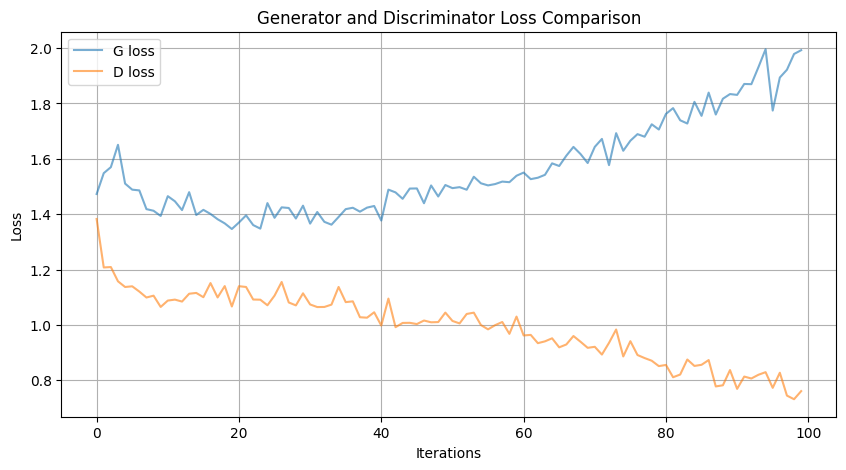

In [236]:
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss Comparison")
plt.plot(G_losses_modified, label="G loss", alpha=0.6)
plt.plot(D_losses_modified, label="D loss", alpha=0.6)
plt.grid(True)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

Berdasarkan grafik generator dan discriminator loss, keduanya berfluktuasi namun ke arah yang berlawanan Nilai Discriminator Loss cenderung menurun seiring bertambahnya epoch, yang mengindikasikan bahwa Discriminator semakin baik dalam membedakan gambar asli dan gambar hasil Generator. Sebaliknya, Generator Loss cenderung meningkat karena Generator menghadapi Discriminator yang semakin kuat, sehingga kesalahan Generator dalam mengelabui Discriminator menjadi lebih besar.

### plot rata-rata gradien generator

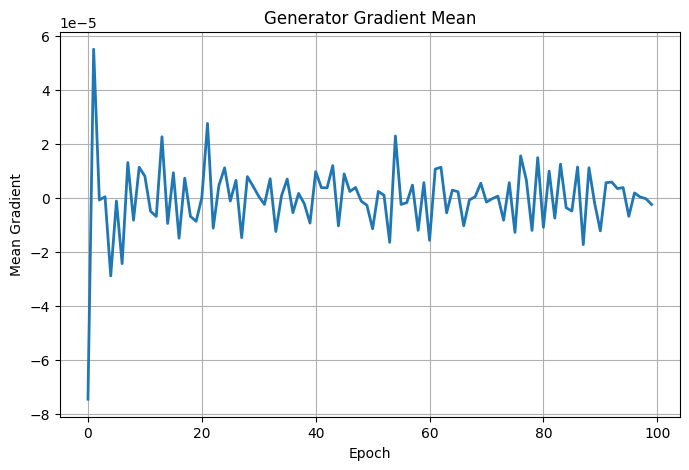

In [237]:
plt.figure(figsize=(8,5))
plt.plot(
    G_grads_mean_modified,
    linewidth=2
)
plt.title("Generator Gradient Mean")
plt.xlabel("Epoch")
plt.ylabel("Mean Gradient")
plt.grid(True)
plt.show()

Pada grafik Generator gradien mean, menunjukkan adanya lonjakan pada awal proses pelatihan, yaitu meningkat dari sekitar nol hingga mendekati 6 pada beberapa epoch pertama. Kondisi ini menunjukkan bahwa Generator menerima sinyal pembelajaran yang besar ketika mulai menyesuaikan parameter dari bobot awal yang masih diinisialisasi secara acak. Setelah fase adaptasi awal tersebut, nilai mean gradien menurun dan berfluktuasi pada rentang sekitar −3 hingga 3 hingga akhir pelatihan. Fluktuasi ini mengindikasikan bahwa Generator tetap menerima gradien yang cukup untuk memperbarui bobotnya selama proses adversarial berlangsung.

### Perhitungan FID

In [248]:
fid_modified = evaluate_fid_modified(netG_modified,test_loader,latent_dim=latent_dim,device=device)
print(f"Modified FID : {fid_modified:.4f}")

Modified FID : 171.7387


Model modifikasi memperoleh nilai 171,7387, jauh lebih rendah dibandingkan model baseline Saturating Loss (490,0497) maupun Non-Saturating Loss (413,6244). Nilai tersebut menunjukkan bahwa distribusi fitur gambar hasil Generator pada model modifikasi lebih mendekati distribusi gambar asli. Dibandingkan model baseline, nilai FID mengalami penurunan sekitar 64,96% terhadap Saturating Loss dan 58,48% terhadap Non-Saturating Loss. Meskipun model belum mencapai target FID (<30), namun penurunan ini menunjukkan bahwa penerapan arsitektur berbasis CNN, Batch Normalization, Spectral Normalization, serta One-Sided Label Smoothing berhasil meningkatkan stabilitas proses pelatihan dan kemampuan Generator dalam menghasilkan gambar yang lebih realistis.

### Perbandingan Real vs Fake

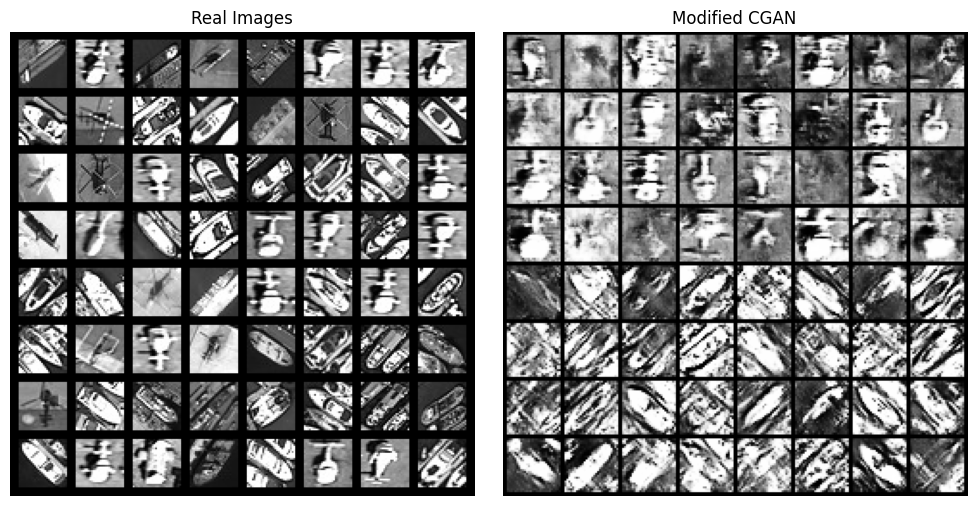

In [245]:
real_batch = next(iter(train_loader))
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(
    np.transpose(
        vutils.make_grid(
            real_batch[0][:64],
            padding=5,
            normalize=True
        ).cpu(),
        (1,2,0)
    )
)

plt.subplot(1,2,2)
plt.axis("off")
plt.title("Modified CGAN")
plt.imshow(
    np.transpose(
        img_list_modified[-1],
        (1,2,0)
    )
)
plt.tight_layout()
plt.show()

Dibandingkan baseline model, kita sekarang bisa sedikit melihat bahwa hasil fake image memiliki bentuk yang mirip dengan gambar asli.